In [ ]:
!pip install wfdb kagglehub -q

In [ ]:
import os
import numpy as np
import pandas as pd
import wfdb
import matplotlib.pyplot as plt

print("Libraries loaded")

Libraries loaded


In [ ]:
import kagglehub
path = kagglehub.dataset_download("ecerulm/apneaecg")


Using Colab cache for faster access to the 'apneaecg' dataset.


In [ ]:
print(os.listdir(path))

['apnea-ecg.zip', 'apnea-ecg']


In [ ]:
DATA_PATH = os.path.join(
    path,
    "apnea-ecg"
)

print(DATA_PATH)

/kaggle/input/apneaecg/apnea-ecg


In [ ]:
record = wfdb.rdrecord(
    os.path.join(DATA_PATH, "a01")
)

print("Sampling frequency:", record.fs)
print("Number of samples:", len(record.p_signal))

Sampling frequency: 100
Number of samples: 2957000


In [ ]:
qrs = wfdb.rdann(
    os.path.join(DATA_PATH, "a01"),
    "qrs"
)

r_peaks = qrs.sample

print("Number of R-peaks:", len(r_peaks))
print("First 20:", r_peaks[:20])

Number of R-peaks: 29938
First 20: [  34  123  207  290  373  461  554  652  746  839  932 1033 1135 1236
 1335 1432 1527 1625 1725 1820]


In [ ]:
apnea = wfdb.rdann(
    os.path.join(DATA_PATH, "a01"),
    "apn"
)

labels = np.array(apnea.symbol)

print("Number of labels:", len(labels))
print("First 20 labels:", labels[:20])

Number of labels: 489
First 20 labels: ['N' 'N' 'N' 'N' 'N' 'N' 'N' 'N' 'N' 'N' 'N' 'N' 'N' 'A' 'A' 'A' 'A' 'A'
 'A' 'A']


In [ ]:
fs = record.fs

rr_intervals = np.diff(r_peaks) / fs

print("Number of RR intervals:", len(rr_intervals))
print("First 20 RR intervals:")
print(rr_intervals[:20])

Number of RR intervals: 29937
First 20 RR intervals:
[0.89 0.84 0.83 0.83 0.88 0.93 0.98 0.94 0.93 0.93 1.01 1.02 1.01 0.99
 0.97 0.95 0.98 1.   0.95 0.9 ]


In [ ]:
FS = 100
WINDOW = 60 * FS

X_a01 = []
y_a01 = []

for i in range(len(labels)):

    # Start and end sample of this 60-second window
    start = i * WINDOW
    end = (i + 1) * WINDOW

    # R-peaks inside this window
    window_peaks = r_peaks[
        (r_peaks >= start) &
        (r_peaks < end)
    ]

    # Need at least 2 R-peaks
    if len(window_peaks) < 2:
        continue

    # RR intervals
    rr = np.diff(window_peaks) / FS

    # Remove unrealistic RR intervals
    rr = rr[
        (rr >= 0.3) &
        (rr <= 2.0)
    ]

    if len(rr) < 2:
        continue

    # Label
    label = 1 if labels[i] == "A" else 0

    X_a01.append(rr)
    y_a01.append(label)

print("Number of sequences:", len(X_a01))
print("Normal:", np.sum(np.array(y_a01) == 0))
print("Apnea:", np.sum(np.array(y_a01) == 1))

Number of sequences: 489
Normal: 19
Apnea: 470


In [ ]:
lengths = [len(x) for x in X_a01]

print("Minimum:", min(lengths))
print("Maximum:", max(lengths))
print("Mean:", np.mean(lengths))
print("Median:", np.median(lengths))

Minimum: 48
Maximum: 82
Mean: 59.67280163599182
Median: 59.0


In [ ]:
print("First sequence:")
print(X_a01[0])

print("\nFirst label:")
print(y_a01[0])

print("\nShape of first sequence:")
print(X_a01[0].shape)

First sequence:
[0.89 0.84 0.83 0.83 0.88 0.93 0.98 0.94 0.93 0.93 1.01 1.02 1.01 0.99
 0.97 0.95 0.98 1.   0.95 0.9  0.85 0.86 0.97 0.93 0.93 0.83 0.78 0.77
 0.81 0.81 0.84 0.84 0.81 0.82 0.9  1.   0.93 0.88 0.86 0.85 0.87 0.89
 0.91 0.92 0.88 0.97 1.   0.94 0.86 0.82 0.83 0.88 0.88 0.88 0.92 0.9
 0.89 0.93 0.9  0.9  0.91 0.91 0.88 0.88 0.93 0.89]

First label:
0

Shape of first sequence:
(66,)


In [ ]:
patient_ids = (
    [f"a{i:02d}" for i in range(1, 21)] +
    [f"b{i:02d}" for i in range(1, 6)] +
    [f"c{i:02d}" for i in range(1, 11)]
)

print(patient_ids)
print("Total patients:", len(patient_ids))

['a01', 'a02', 'a03', 'a04', 'a05', 'a06', 'a07', 'a08', 'a09', 'a10', 'a11', 'a12', 'a13', 'a14', 'a15', 'a16', 'a17', 'a18', 'a19', 'a20', 'b01', 'b02', 'b03', 'b04', 'b05', 'c01', 'c02', 'c03', 'c04', 'c05', 'c06', 'c07', 'c08', 'c09', 'c10']
Total patients: 35


In [ ]:
def process_patient(patient_id):

    # Read QRS annotations
    qrs = wfdb.rdann(
        os.path.join(DATA_PATH, patient_id),
        "qrs"
    )

    r_peaks = qrs.sample

    # Read apnea annotations
    apnea = wfdb.rdann(
        os.path.join(DATA_PATH, patient_id),
        "apn"
    )

    labels = np.array(apnea.symbol)

    X_patient = []
    y_patient = []

    for i, label in enumerate(labels):

        start = i * 60 * FS
        end = (i + 1) * 60 * FS

        # R-peaks within this minute
        window_peaks = r_peaks[
            (r_peaks >= start) &
            (r_peaks < end)
        ]

        if len(window_peaks) < 2:
            continue

        # RR intervals
        rr = np.diff(window_peaks) / FS

        # Remove unrealistic RR intervals
        rr = rr[
            (rr >= 0.3) &
            (rr <= 2.0)
        ]

        if len(rr) < 2:
            continue

        # Convert label
        target = 1 if label == "A" else 0

        X_patient.append(rr)
        y_patient.append(target)

    return X_patient, y_patient

In [ ]:
X_test_a01, y_test_a01 = process_patient("a01")

print("Samples:", len(X_test_a01))
print("Normal:", np.sum(np.array(y_test_a01) == 0))
print("Apnea:", np.sum(np.array(y_test_a01) == 1))

Samples: 489
Normal: 19
Apnea: 470


In [ ]:
all_X = []
all_y = []
all_patient_ids = []

for patient in patient_ids:

    try:

        X_patient, y_patient = process_patient(patient)

        all_X.extend(X_patient)
        all_y.extend(y_patient)

        all_patient_ids.extend(
            [patient] * len(y_patient)
        )

        print(
            patient,
            "→",
            len(y_patient),
            "samples"
        )

    except Exception as e:

        print(
            patient,
            "ERROR:",
            e
        )

a01 → 489 samples
a02 → 528 samples
a03 → 519 samples
a04 → 492 samples
a05 → 454 samples
a06 → 510 samples
a07 → 511 samples
a08 → 501 samples
a09 → 495 samples
a10 → 517 samples
a11 → 466 samples
a12 → 577 samples
a13 → 495 samples
a14 → 509 samples
a15 → 510 samples
a16 → 482 samples
a17 → 484 samples
a18 → 489 samples
a19 → 502 samples
a20 → 510 samples
b01 → 487 samples
b02 → 517 samples
b03 → 441 samples
b04 → 426 samples
b05 → 433 samples
c01 → 479 samples
c02 → 494 samples
c03 → 454 samples
c04 → 477 samples
c05 → 466 samples
c06 → 468 samples
c07 → 429 samples
c08 → 513 samples
c09 → 457 samples
c10 → 425 samples


In [ ]:
print("\nTotal samples:", len(all_X))
print("Total patients:", len(set(all_patient_ids)))

print(
    "Normal:",
    np.sum(np.array(all_y) == 0)
)

print(
    "Apnea:",
    np.sum(np.array(all_y) == 1)
)


Total samples: 17006
Total patients: 35
Normal: 10493
Apnea: 6513


In [ ]:
all_y = np.array(all_y)
all_patient_ids = np.array(all_patient_ids)

print(all_y.shape)
print(all_patient_ids.shape)

(17006,)
(17006,)


In [ ]:
all_lengths = np.array([len(x) for x in all_X])

print("Minimum:", all_lengths.min())
print("Maximum:", all_lengths.max())
print("Mean:", all_lengths.mean())
print("Median:", np.median(all_lengths))
print("95th percentile:", np.percentile(all_lengths, 95))
print("99th percentile:", np.percentile(all_lengths, 99))

Minimum: 2
Maximum: 111
Mean: 63.97012819005057
Median: 63.0
95th percentile: 80.0
99th percentile: 87.0


In [ ]:
MIN_RR = 30

filtered_X = []
filtered_y = []
filtered_patients = []

for x, label, patient in zip(
    all_X, all_y, all_patient_ids
):
    if len(x) >= MIN_RR:
        filtered_X.append(x)
        filtered_y.append(label)
        filtered_patients.append(patient)

all_X = filtered_X
all_y = np.array(filtered_y)
all_patient_ids = np.array(filtered_patients)

print("Samples after filtering:", len(all_X))
print("Normal:", np.sum(all_y == 0))
print("Apnea:", np.sum(all_y == 1))

Samples after filtering: 16862
Normal: 10406
Apnea: 6456


In [ ]:
from sklearn.model_selection import train_test_split

unique_patients = np.unique(all_patient_ids)

train_patients, temp_patients = train_test_split(
    unique_patients,
    test_size=0.30,
    random_state=42
)

val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=42
)

print("Training patients:", len(train_patients))
print("Validation patients:", len(val_patients))
print("Test patients:", len(test_patients))

print("\nTrain:", train_patients)
print("Validation:", val_patients)
print("Test:", test_patients)

Training patients: 24
Validation patients: 5
Test patients: 6

Train: ['c09' 'a01' 'a05' 'a18' 'c03' 'a06' 'a12' 'a02' 'a03' 'c08' 'a04' 'c06'
 'b04' 'c07' 'a11' 'b03' 'a19' 'c01' 'a07' 'b01' 'c10' 'a08' 'a15' 'c04']
Validation: ['a09' 'a16' 'a13' 'b02' 'a20']
Test: ['c05' 'c02' 'a17' 'a10' 'b05' 'a14']


In [ ]:
X_train = []
y_train = []

X_val = []
y_val = []

X_test = []
y_test = []

for x, label, patient in zip(
    all_X, all_y, all_patient_ids
):

    if patient in train_patients:
        X_train.append(x)
        y_train.append(label)

    elif patient in val_patients:
        X_val.append(x)
        y_val.append(label)

    elif patient in test_patients:
        X_test.append(x)
        y_test.append(label)

In [ ]:
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

print("Train samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

Train samples: 11470
Validation samples: 2497
Test samples: 2895


In [ ]:
print("\nTRAIN")
print("Normal:", np.sum(y_train == 0))
print("Apnea:", np.sum(y_train == 1))

print("\nVALIDATION")
print("Normal:", np.sum(y_val == 0))
print("Apnea:", np.sum(y_val == 1))

print("\nTEST")
print("Normal:", np.sum(y_test == 0))
print("Apnea:", np.sum(y_test == 1))


TRAIN
Normal: 7067
Apnea: 4403

VALIDATION
Normal: 1145
Apnea: 1352

TEST
Normal: 2194
Apnea: 701


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_rr_values = np.concatenate(X_train).reshape(-1, 1)

scaler.fit(train_rr_values)

StandardScaler()

In [ ]:
X_train = [
    scaler.transform(x.reshape(-1, 1)).flatten()
    for x in X_train
]

X_val = [
    scaler.transform(x.reshape(-1, 1)).flatten()
    for x in X_val
]

X_test = [
    scaler.transform(x.reshape(-1, 1)).flatten()
    for x in X_test
]

In [ ]:
from tensorflow.keras.utils import pad_sequences

MAX_LEN = 87
MASK_VALUE = -10.0

X_train = pad_sequences(
    X_train,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
    dtype="float32",
    value=MASK_VALUE
)

X_val = pad_sequences(
    X_val,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
    dtype="float32",
    value=MASK_VALUE
)

X_test = pad_sequences(
    X_test,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
    dtype="float32",
    value=MASK_VALUE
)

In [ ]:
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (11470, 87, 1, 1)
X_val: (2497, 87, 1, 1)
X_test: (2895, 87, 1, 1)


In [ ]:
from sklearn.utils import resample
import numpy as np

# Separate classes
X_normal = X_train[y_train == 0]
X_apnea  = X_train[y_train == 1]

# Undersample Normal to match Apnea
X_normal_balanced = resample(
    X_normal,
    replace=False,
    n_samples=len(X_apnea),
    random_state=42
)

# Combine
X_train_balanced = np.concatenate(
    [X_normal_balanced, X_apnea],
    axis=0
)

y_train_balanced = np.concatenate(
    [
        np.zeros(len(X_normal_balanced)),
        np.ones(len(X_apnea))
    ]
)

# Shuffle
idx = np.random.permutation(len(y_train_balanced))

X_train_balanced = X_train_balanced[idx]
y_train_balanced = y_train_balanced[idx]

print("Balanced training data:")
print("Normal:", np.sum(y_train_balanced == 0))
print("Apnea :", np.sum(y_train_balanced == 1))

Balanced training data:
Normal: 4403
Apnea : 4403


In [ ]:
!pip install -q keras-tuner

In [ ]:
import keras_tuner as kt
print(kt.__version__)

1.4.8


In [ ]:
def build_lstm_model(hp):

    model = keras.Sequential()

    model.add(
        keras.Input(shape=(87, 1))
    )

    # Mask padding
    model.add(
        layers.Masking(mask_value=-10.0)
    )

    # Number of LSTM layers
    num_lstm_layers = hp.Int(
        "num_lstm_layers",
        min_value=1,
        max_value=3,
        step=1
    )

    for i in range(num_lstm_layers):

        units = hp.Int(
            f"lstm_units_{i}",
            min_value=32,
            max_value=128,
            step=32
        )

        activation = hp.Choice(
            f"lstm_activation_{i}",
            ["tanh", "relu"]
        )

        dropout = hp.Float(
            f"lstm_dropout_{i}",
            min_value=0.1,
            max_value=0.5,
            step=0.1
        )

        # All LSTM layers except final one
        if i < num_lstm_layers - 1:
            return_sequences = True
        else:
            return_sequences = False

        model.add(
            layers.LSTM(
                units=units,
                activation=activation,

                kernel_initializer="glorot_uniform",
                recurrent_initializer="orthogonal",
                bias_initializer="zeros",

                return_sequences=return_sequences
            )
        )

        model.add(
            layers.Dropout(dropout)
        )

    # Dense layer
    dense_units = hp.Int(
        "dense_units",
        min_value=8,
        max_value=64,
        step=8
    )

    dense_activation = hp.Choice(
        "dense_activation",
        ["relu", "tanh"]
    )

    dense_initializer = (
        "he_normal"
        if dense_activation == "relu"
        else "glorot_uniform"
    )

    model.add(
        layers.Dense(
            dense_units,
            activation=dense_activation,
            kernel_initializer=dense_initializer,
            bias_initializer="zeros"
        )
    )

    # Final output
    model.add(
        layers.Dense(
            1,
            activation="sigmoid",
            kernel_initializer="glorot_uniform",
            bias_initializer="zeros"
        )
    )

    # Learning rate
    learning_rate = hp.Float(
        "learning_rate",
        min_value=1e-4,
        max_value=3e-3,
        sampling="log"
    )

    optimizer = keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

    return model

In [ ]:
tuner = kt.RandomSearch(
    build_lstm_model,

    objective=kt.Objective(
        "val_auc",
        direction="max"
    ),

    max_trials=4,

    directory="random_lstm_tuning",
    project_name="sleep_apnea",
    overwrite=True
)

In [ ]:
# tuner = kt.Hyperband(
#     build_lstm_model,

#     objective=kt.Objective(
#         "val_auc",
#         direction="max"
#     ),

#     max_epochs=30,
#     factor=3,
#     hyperband_iterations=2,

#     directory="lstm_tuning",
#     project_name="sleep_apnea_lstm",
#     overwrite=True
# )

In [ ]:
# tuner = kt.RandomSearch(
#     build_lstm_model,

#     objective= "val_auc",

#     max_trials=20
# )

In [ ]:
tuner.search_space_summary()

Search space summary
Default search space size: 7
num_lstm_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
lstm_units_0 (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 128, 'step': 32, 'sampling': 'linear'}
lstm_activation_0 (Choice)
{'default': 'tanh', 'conditions': [], 'values': ['tanh', 'relu'], 'ordered': False}
lstm_dropout_0 (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
dense_units (Int)
{'default': None, 'conditions': [], 'min_value': 8, 'max_value': 64, 'step': 8, 'sampling': 'linear'}
dense_activation (Choice)
{'default': 'relu', 'conditions': [], 'values': ['relu', 'tanh'], 'ordered': False}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.003, 'step': None, 'sampling': 'log'}


In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=5,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_auc",
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

In [ ]:
# from sklearn.utils.class_weight import compute_class_weight
# import numpy as np

# classes = np.unique(y_train)

# weights = compute_class_weight(
#     class_weight="balanced",
#     classes=classes,
#     y=y_train
# )

# class_weights = dict(zip(classes, weights))

# print(class_weights)

{np.int64(0): np.float64(0.8115183246073299), np.int64(1): np.float64(1.3025210084033614)}


In [ ]:
tuner.search(
    X_train_balanced,
    y_train_balanced,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Trial 4 Complete [00h 00m 13s]
val_auc: 0.8145058155059814

Best val_auc So Far: 0.8145058155059814
Total elapsed time: 00h 06m 35s


In [ ]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("BEST HYPERPARAMETERS")
for key, value in best_hp.values.items():
    print(key, ":", value)

BEST HYPERPARAMETERS
num_lstm_layers : 1
lstm_units_0 : 32
lstm_activation_0 : tanh
lstm_dropout_0 : 0.2
dense_units : 40
dense_activation : tanh
learning_rate : 0.0008892113867127771
lstm_units_1 : 32
lstm_activation_1 : tanh
lstm_dropout_1 : 0.4
lstm_units_2 : 32
lstm_activation_2 : relu
lstm_dropout_2 : 0.5


In [ ]:
best_model = tuner.get_best_models(num_models=1)[0]

y_prob = best_model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Apnea"]
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

 1/91 ━━━━━━━━━━━━━━━━━━━━ 11s 130ms/step

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 16 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
              precision    recall  f1-score   support

      Normal       0.88      0.45      0.59      2194
       Apnea       0.32      0.81      0.46       701

    accuracy                           0.53      2895
   macro avg       0.60      0.63      0.52      2895
weighted avg       0.74      0.53      0.56      2895

ROC-AUC: 0.7630374370771278


In [ ]:
best_model = tuner.hypermodel.build(best_hp)

best_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ masking_1 (Masking)             │ (None, 87, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 40)             │         1,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            41 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,713 (22.32 KB)

 Trainable params: 5,713 (22.32 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

In [ ]:
history = best_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    initial_epoch=12,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 13/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.7596 - auc: 0.8430 - loss: 0.4889 - precision: 0.6659 - recall: 0.7504 - val_accuracy: 0.7241 - val_auc: 0.8047 - val_loss: 0.5465 - val_precision: 0.7802 - val_recall: 0.6827 - learning_rate: 2.2230e-04
Epoch 14/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7573 - auc: 0.8469 - loss: 0.4830 - precision: 0.6607 - recall: 0.7558 - val_accuracy: 0.7225 - val_auc: 0.8132 - val_loss: 0.5435 - val_precision: 0.7945 - val_recall: 0.6575 - learning_rate: 2.2230e-04
Epoch 15/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7575 - auc: 0.8460 - loss: 0.4840 - precision: 0.6600 - recall: 0.7595 - val_accuracy: 0.7245 - val_auc: 0.8119 - val_loss: 0.5410 - val_precision: 0.7897 - val_recall: 0.6694 - learning_rate: 2.2230e-04
Epoch 16/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7582 - auc: 0.8468 - loss: 0.4831 - precision: 0.6599 - recall: 0.7636 - val_accuracy: 0.7121 - val_auc: 0.8087 - val_lo

In [ ]:
y_prob = model.predict(X_test).ravel()

y_pred = (y_prob >= 0.5).astype(int)

from sklearn.metrics import classification_report, roc_auc_score

print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Apnea"]
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
              precision    recall  f1-score   support

      Normal       0.82      0.94      0.88      2194
       Apnea       0.65      0.36      0.46       701

    accuracy                           0.80      2895
   macro avg       0.74      0.65      0.67      2895
weighted avg       0.78      0.80      0.78      2895

ROC-AUC: 0.5769798191670449


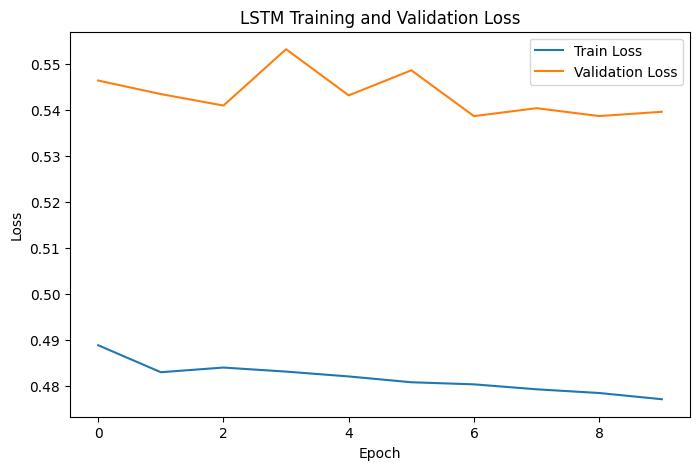

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.show()

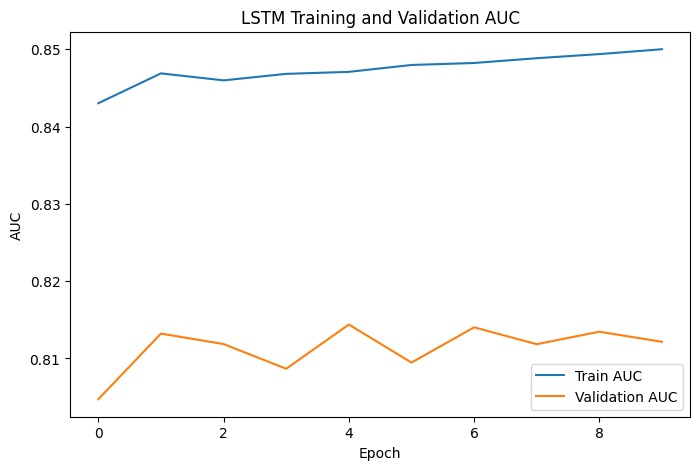

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["auc"], label="Train AUC")
plt.plot(history.history["val_auc"], label="Validation AUC")

plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.title("LSTM Training and Validation AUC")
plt.legend()
plt.show()

In [ ]:
test_results = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

91/91 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7990 - auc: 0.5546 - loss: 0.6897 - precision: 0.6545 - recall: 0.3595
loss: 0.6897
compile_metrics: 0.7990


In [ ]:
cm = confusion_matrix(y_test, y_pred)

print(cm)


[[2061  133]
 [ 449  252]]


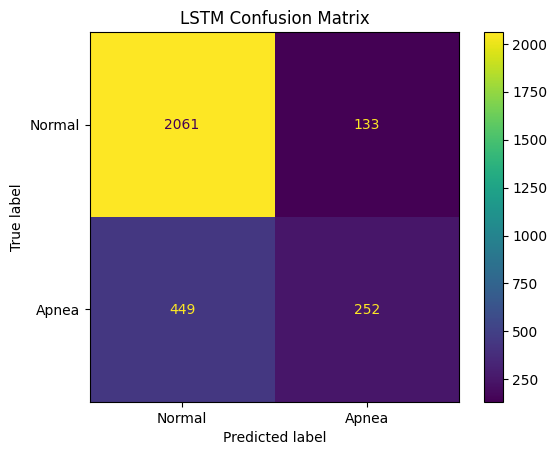

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Apnea"]
).plot()

plt.title("LSTM Confusion Matrix")
plt.show()